# Тюнинг линейной регрессии и ошибки

### О задании

В этом задании вы:
- обучите линейную регрессию, познакомитесь с метриками качества в задачах регресии

In [17]:
%pylab inline
import pandas as pd

from sklearn.base import BaseEstimator
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


## Часть 1. Линейная регрессия

Для начала загрузим данные и разделим их на обучающую и тестовую выборки в соотношении 7 к 3. Зачем так делать? Когда вы проверяете себя на данных на которых не обучались, вы можете быть уверены что не переобучились. Таким образом если качество на 70% датасета (оубчающей выборке) растёт, а на тестовой выборке падает, то модель начала запоминать датасет (переобучилась), вы что-то делаете не так.


In [3]:
data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, train_size=0.7, random_state=241)

In [23]:
data

{'data': array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
          0.01990749, -0.01764613],
        [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
         -0.06833155, -0.09220405],
        [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
          0.00286131, -0.02593034],
        ...,
        [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
         -0.04688253,  0.01549073],
        [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
          0.04452873, -0.02593034],
        [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
         -0.00422151,  0.00306441]], shape=(442, 10)),
 'target': array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
         69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
         68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
         87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
        259.,  53., 190., 142.,  75., 142.

In [4]:
X_train.shape

(309, 10)

__Задание 1.__ Обучение линейной регрессии.

**(4 балла)**

Обучите линейную регрессию с $L_1$ (Lasso) и $L_2$ (Ridge) регуляризаторами (используйте параметры по умолчанию). Посмотрите, какое количество коэффициентов близко к 0 (степень близости к 0 определите сами из разумных пределов). Постройте график зависимости числа ненулевых коэффициентов от коэффицента регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$).

Спойлер - при большом гиперпараметре регуляризации все параметры стремятся к нулю. На графике это должно быть видно.

Постройте графики коэффициентов регрессии от итерации обучения

In [5]:
from sklearn import datasets, linear_model
from sklearn.linear_model import Ridge, Lasso, ElasticNet
import numpy as np
from sklearn.metrics import mean_squared_error

/Users/ovsyannikovleonid/Jupyter notebooks/aesc_ml/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.975451e+05, tolerance: 1.915e+02
  model = cd_fast.enet_coordinate_descent(
/Users/ovsyannikovleonid/Jupyter notebooks/aesc_ml/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.679732e+05, tolerance: 1.915e+02
  model = cd_fast.enet_coordinate_descent(
/Users/ovsyannikovleonid/Jupyter notebooks/aesc_ml/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to inc

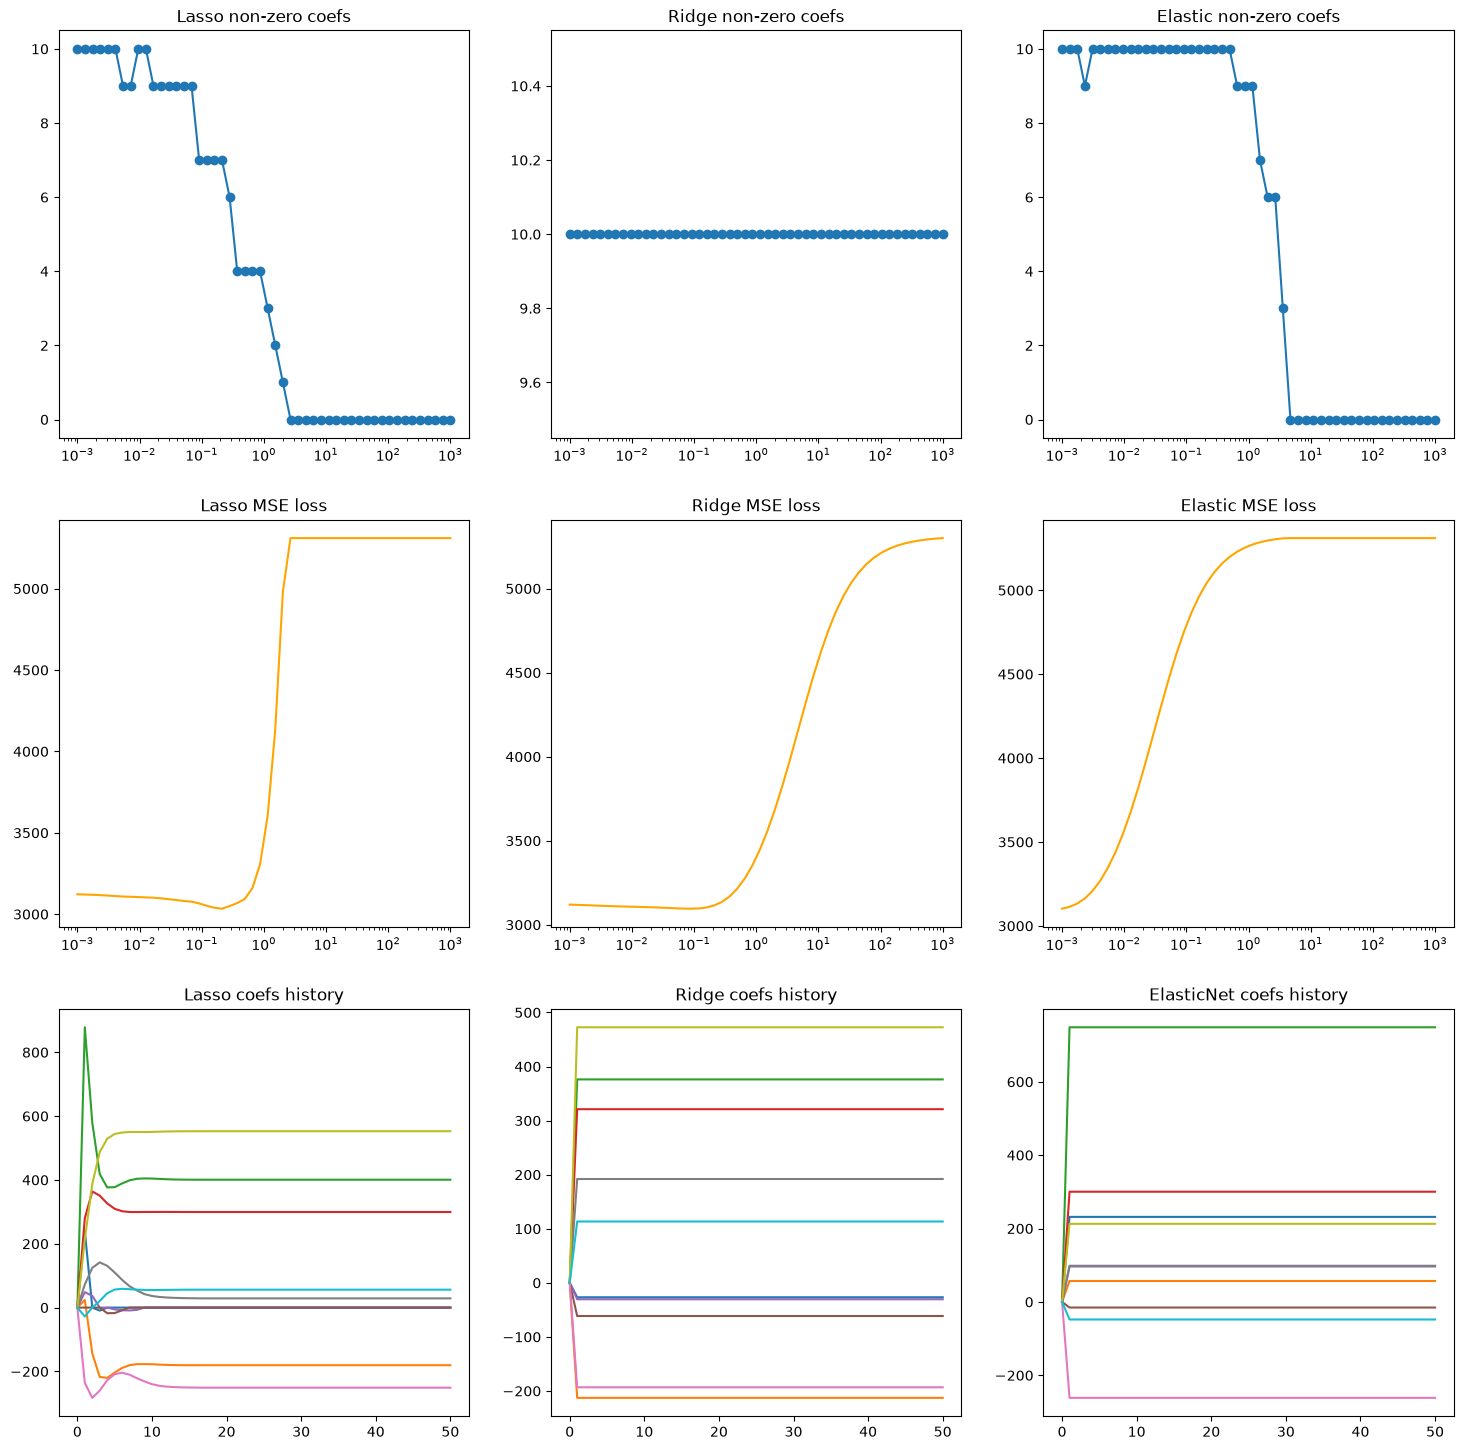

In [31]:
import matplotlib.pyplot as plt

y_lasso = []
y_ridge = []
y_elastic = []

x_lasso = []
x_ridge = []
x_elastic = []

lasso_losses = []
ridge_losses = []
elastic_losses = []

for degree in np.logspace(-3, 3, 50):
    degree = float(degree)
    model = linear_model.Lasso(alpha=degree)
    
    model.fit(X_train, y_train)
    
    a = (np.abs(model.coef_) > 1e-2).sum()
    y_lasso.append(degree)
    x_lasso.append(a)
    lasso_losses.append(mean_squared_error(y_test, model.predict(X_test)))

    model = linear_model.Ridge(alpha=degree)
    
    model.fit(X_train, y_train)

    a = (np.abs(model.coef_) > 1e-2).sum()
    y_ridge.append(degree)
    x_ridge.append(a)
    ridge_losses.append(mean_squared_error(y_test, model.predict(X_test)))

    model = linear_model.ElasticNet(alpha=degree)
    
    model.fit(X_train, y_train)
    
    a = (np.abs(model.coef_) > 1e-2).sum()
    y_elastic.append(degree)
    x_elastic.append(a)
    elastic_losses.append(mean_squared_error(y_test, model.predict(X_test)))

fig, axs = plt.subplots(3, 3, figsize=(18, 18))

axs[0, 0].scatter(y_lasso, x_lasso)
axs[0, 0].plot(y_lasso, x_lasso)
axs[0, 0].set_xscale("log")
axs[0, 0].set_title("Lasso non-zero coefs")

axs[1, 0].plot(y_lasso, lasso_losses, color="orange")
axs[1, 0].set_xscale("log")
axs[1, 0].set_title("Lasso MSE loss")

axs[0, 1].scatter(y_ridge, x_ridge)
axs[0, 1].plot(y_ridge, x_ridge)
axs[0, 1].set_xscale("log")
axs[0, 1].set_title("Ridge non-zero coefs")

axs[1, 1].plot(y_lasso, ridge_losses, color="orange")
axs[1, 1].set_xscale("log")
axs[1, 1].set_title("Ridge MSE loss")

axs[0, 2].scatter(y_elastic, x_elastic)
axs[0, 2].plot(y_elastic, x_elastic)
axs[0, 2].set_xscale("log")
axs[0, 2].set_title("Elastic non-zero coefs")

axs[1, 2].plot(y_lasso, elastic_losses, color="orange")
axs[1, 2].set_xscale("log")
axs[1, 2].set_title("Elastic MSE loss")


coefs = np.zeros(X_train.shape[1])
rang = np.arange(0, 51)

lasso_history = np.zeros((51, X_train.shape[1]))

for itr in range(1, 51):
    model = linear_model.Lasso(alpha=1e-1, max_iter=1, warm_start=True)
    model.coef_= coefs
    model.fit(X_train, y_train)
    coefs = model.coef_
    lasso_history[itr] = coefs

for i in range(X_train.shape[1]):
    axs[2, 0].plot(rang, lasso_history[:, i])

axs[2, 0].set_title("Lasso coefs history")

coefs = np.zeros(X_train.shape[1])
rang = np.arange(0, 51)

ridge_history = np.zeros((51, X_train.shape[1]))

for itr in range(1, 51):
    model = linear_model.Ridge(alpha=1e-1, max_iter=1)
    model.coef_= coefs
    model.fit(X_train, y_train)
    coefs = model.coef_
    ridge_history[itr] = coefs

for i in range(X_train.shape[1]):
    axs[2, 1].plot(rang, ridge_history[:, i])

axs[2, 1].set_title("Ridge coefs history")

coefs = np.zeros(X_train.shape[1])
rang = np.arange(0, 51)

elastic_history = np.zeros((51, X_train.shape[1]))

for itr in range(1, 51):
    model = linear_model.ElasticNet(alpha=1e-3, max_iter=1)
    model.coef_= coefs
    model.fit(X_train, y_train)
    coefs = model.coef_
    elastic_history[itr] = coefs

for i in range(X_train.shape[1]):
    axs[2, 2].plot(rang, elastic_history[:, i])

axs[2, 2].set_title("ElasticNet coefs history")

plt.show()

Посчитайте для Ridge-регрессии следующие метрики: $RMSE$, $MAE$, $R^2$.

In [ ]:
from sklearn.cross_validation import cross_val_score
from sklearn.cross_validation import cross_val_predict

In [87]:
# code here

from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

model = linear_model.Ridge()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(f"RMSE: {root_mean_squared_error(y_test, y_pred):.3f}, MAE: {mean_absolute_error(y_test, y_pred):.3f}, R^2: {r2_score(y_test, y_pred):.3f}")

RMSE: 58.304, MAE: 49.603, R^2: 0.360


Подберите на обучающей выборке для Ridge-регрессии коэффициент регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$) для каждой из метрик. Постройте графики зависимости фукнции потерь от коэффициента регуляризации. Посчитайте те же метрики снова. Заметно ли изменилось качество?

RMSE
RMSE: 55.858, MAE: 47.155, R^2: 0.412
MAE
RMSE: 55.858, MAE: 47.155, R^2: 0.412
R^2
RMSE: 55.858, MAE: 47.155, R^2: 0.412


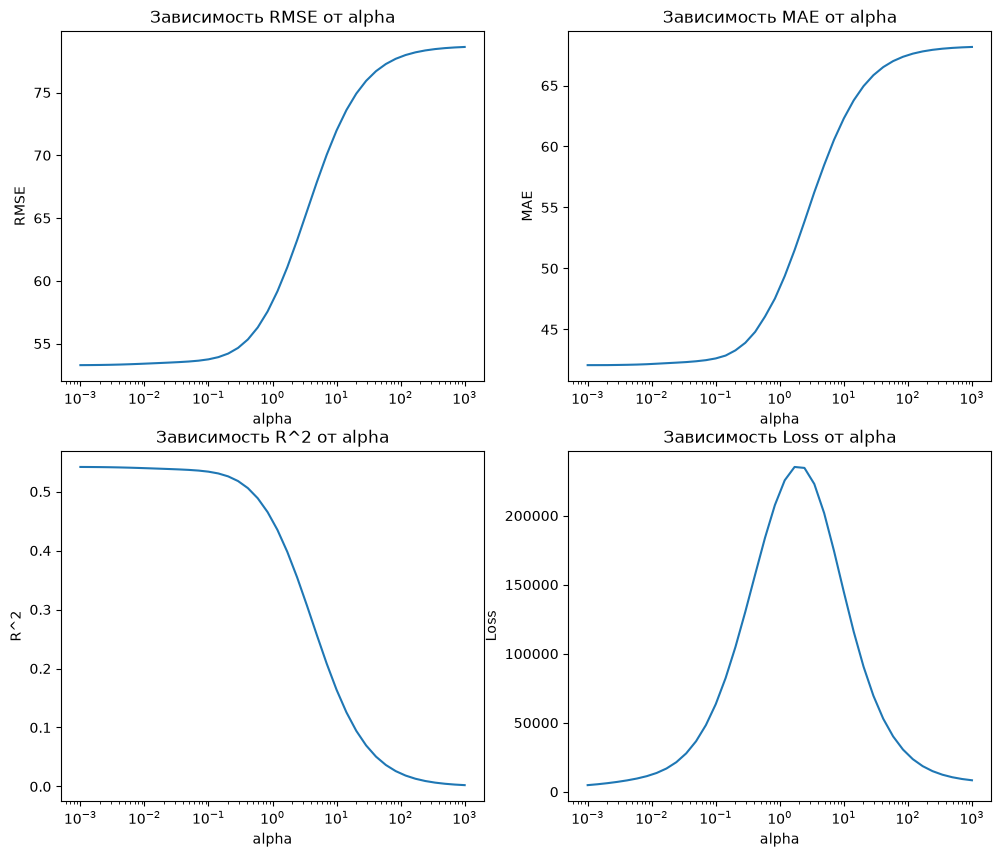

In [99]:
# code here

from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
import seaborn as sns

losses = []
rmses = []
maes = []
r2s = []

for alpha in np.logspace(-3, 3, 40):
    model = linear_model.Ridge(alpha=alpha)
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_train)

    mse = (y_train-y_pred)**2
    loss = mse + (alpha * np.linalg.norm(model.coef_) ** 2)

    
    losses.append(sum(loss)/len(loss))
    rmses.append(root_mean_squared_error(y_train, y_pred))
    maes.append(mean_absolute_error(y_train, y_pred))
    r2s.append(r2_score(y_train, y_pred))

fig, axs = plt.subplots(2, 2, figsize=(12, 10))

axs[0][0].plot(np.logspace(-3, 3, 40), rmses)
axs[0][0].set_xscale("log")
axs[0][0].set_ylabel("RMSE")
axs[0][0].set_xlabel("alpha")
axs[0][0].set_title("Зависимость RMSE от alpha")

axs[0][1].plot(np.logspace(-3, 3, 40), maes)
axs[0][1].set_xscale("log")
axs[0][1].set_ylabel("MAE")
axs[0][1].set_xlabel("alpha")
axs[0][1].set_title("Зависимость MAE от alpha")

axs[1][0].plot(np.logspace(-3, 3, 40), r2s)
axs[1][0].set_xscale("log")
axs[1][0].set_ylabel("R^2")
axs[1][0].set_xlabel("alpha")
axs[1][0].set_title("Зависимость R^2 от alpha")

axs[1][1].plot(np.logspace(-3, 3, 40), losses)
axs[1][1].set_xscale("log")
axs[1][1].set_ylabel("Loss")
axs[1][1].set_xlabel("alpha")
axs[1][1].set_title("Зависимость Loss от alpha")

alphas = np.logspace(-3, 3, 40)

def check(alpha):
    model = linear_model.Ridge(alpha=alpha)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    print(f"RMSE: {root_mean_squared_error(y_test, y_pred):.3f}, MAE: {mean_absolute_error(y_test, y_pred):.3f}, R^2: {r2_score(y_test, y_pred):.3f}")

print("RMSE")
check(alphas[np.argmin(rmses)])
print("MAE")
check(alphas[np.argmin(maes)])
print("R^2")
check(alphas[np.argmax(r2s)])

plt.show()

__Задание 2.__ Поиск объектов-выбросов

**(4 балла)**

Как известно, MSE сильно штрафует за большие ошибки на объектах-выбросах. Посчитайте ошибки и посмотрите на их распределение (plt.hist). Что вы видите?

RMSE: 55.919, MAE: 47.199, R^2: 0.411


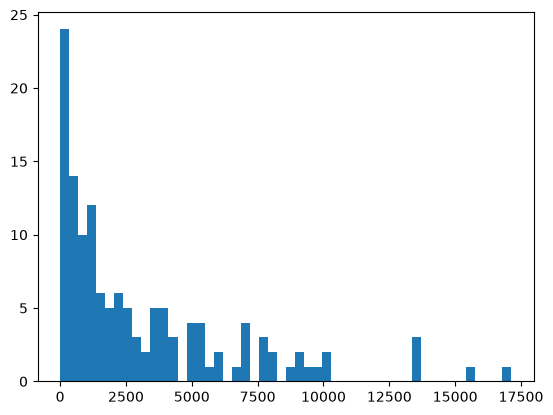

In [122]:
# code here

data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, train_size=0.7, random_state=241)

model = linear_model.LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mses = (y_test-y_pred) ** 2

fig, ax = plt.subplots()

ax.hist(mses, bins=50)

print(f"RMSE: {root_mean_squared_error(y_test, y_pred):.3f}, MAE: {mean_absolute_error(y_test, y_pred):.3f}, R^2: {r2_score(y_test, y_pred):.3f}")

plt.show()

RMSE: 53.281, MAE: 42.092, R^2: 0.542


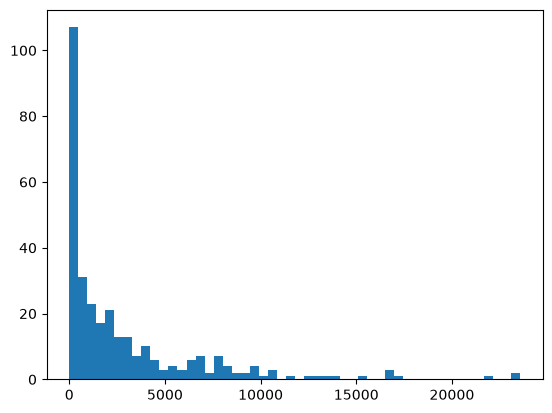

In [129]:
# code here

data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, train_size=0.7, random_state=241)

model = linear_model.LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_train)
train_mses = (y_train-y_pred) ** 2

fig, ax = plt.subplots()

ax.hist(train_mses, bins=50)

print(f"RMSE: {root_mean_squared_error(y_train, y_pred):.3f}, MAE: {mean_absolute_error(y_train, y_pred):.3f}, R^2: {r2_score(y_train, y_pred):.3f}")

plt.show()

Попробуйте удалить объекты-выбросы из обучающей выборки (что считать или не считать выбросами на ваше усмотрение). Обучите модель заново и посмотрите на качество на отложенной выборке (учитывайте, что там тоже могут быть выбросы, с которыми вы ничего не можете сделать). Стало ли лучше? Чем вы можете объяснить это?

In [136]:
# code here

# Самым примитивным способом по mse на трейне

for threshold in np.linspace(1_000, 15_000, 29):
    data = load_diabetes()
    X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, train_size=0.7, random_state=241)

    x_train_len = len(X_train)
    
    X_train = X_train[train_mses < threshold]
    y_train = y_train[train_mses < threshold]
    
    model = linear_model.LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mses = (y_test-y_pred) ** 2
    
    # fig, ax = plt.subplots()
    
    # ax.hist(mses, bins=50)
    print(f"threshold {threshold} | objects deleted {x_train_len-len(X_train)} / {x_train_len}")
    print(f"RMSE: {root_mean_squared_error(y_test, y_pred):.3f}, MAE: {mean_absolute_error(y_test, y_pred):.3f}, R^2: {r2_score(y_test, y_pred):.3f}")
    print("\n")
    
    # plt.show()

threshold 1000.0 | objects deleted 167 / 309
RMSE: 55.938, MAE: 47.196, R^2: 0.411


threshold 1500.0 | objects deleted 147 / 309
RMSE: 55.248, MAE: 46.680, R^2: 0.425


threshold 2000.0 | objects deleted 124 / 309
RMSE: 55.816, MAE: 47.140, R^2: 0.413


threshold 2500.0 | objects deleted 108 / 309
RMSE: 55.777, MAE: 46.913, R^2: 0.414


threshold 3000.0 | objects deleted 92 / 309
RMSE: 55.461, MAE: 46.720, R^2: 0.421


threshold 3500.0 | objects deleted 81 / 309
RMSE: 55.955, MAE: 46.914, R^2: 0.410


threshold 4000.0 | objects deleted 70 / 309
RMSE: 55.716, MAE: 46.787, R^2: 0.415


threshold 4500.0 | objects deleted 64 / 309
RMSE: 55.572, MAE: 46.431, R^2: 0.418


threshold 5000.0 | objects deleted 59 / 309
RMSE: 56.332, MAE: 46.811, R^2: 0.402


threshold 5500.0 | objects deleted 54 / 309
RMSE: 56.737, MAE: 47.044, R^2: 0.394


threshold 6000.0 | objects deleted 51 / 309
RMSE: 56.825, MAE: 47.241, R^2: 0.392


threshold 6500.0 | objects deleted 45 / 309
RMSE: 57.188, MAE: 47.470, R

__Задание 3.__ Отчёт

**(2 балла)**

In [ ]:
# code here